# HSE 2024: Mathematical Methods for Data Analysis

## Homework 2

# Attention!

* For tasks where <ins>text answer</ins> is required **Russian language** is **allowed**.
* If a task asks you to describe something (make coclusions) then **text answer** is **mandatory** and **is** part of the task
* **Do not** upload the dataset (titanic.csv) to the grading system (we already have it)
* We **only** accept **ipynb** notebooks. If you use Google Colab then you'll have to download the notebook before passing the homework
* **Do not** use python loops instead of NumPy vector operations over NumPy vectors - it significantly decreases performance (see why https://blog.paperspace.com/numpy-optimization-vectorization-and-broadcasting/), will be punished with -0.25 for **every** task.
Loops are only allowed in part 1 (Tasks 1 - 4).
* Some tasks contain tests. They only test you solution on a simple example, thus, passing the test does **not** guarantee you the full grade for the task.

If the task asks for an explanation of something, it means that a written answer is required, which is part of the task and is assessed

We only accept ipynb notebooks. If you use Google Colab, you need to download the notebook before submitting your homework

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn import datasets
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLSResults
from math import sqrt
import random
import sys

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

sns.set(style="darkgrid")

### Data

For this homework we will use a dataset of tracks from the streaming service Spotify

**Описание данных**

- **track_id:** The Spotify ID for the track
- **artists:** The artists' names who performed the track. If there is more than one artist, they are separated by a ;
- **album_name:** The album name in which the track appears
- **track_name:** Name of the track
- **popularity:** The popularity of a track is a value between 0 and 100, with 100 being the most popular. The popularity is calculated by algorithm and is based, in the most part, on the total number of plays the track has had and how recent those plays are. Generally speaking, songs that are being played a lot now will have a higher popularity than songs that were played a lot in the past. Duplicate tracks (e.g. the same track from a single and an album) are rated independently. Artist and album popularity is derived mathematically from track popularity.
- **duration_ms:** The track length in milliseconds
- **explicit:** Whether or not the track has explicit lyrics (true = yes it does; false = no it does not OR unknown)
- **danceability:** Danceability describes how suitable a track is for dancing based on a combination of musical elements including tempo, rhythm stability, beat strength, and overall regularity. A value of 0.0 is least danceable and 1.0 is most danceable
- **key:** The key the track is in. Integers map to pitches using standard Pitch Class notation. E.g. 0 = C, 1 = C♯/D♭, 2 = D, and so on. If no key was detected, the value is -1
- **loudness:** The overall loudness of a track in decibels (dB)
- **mode:** Mode indicates the modality (major or minor) of a track, the type of scale from which its melodic content is derived. Major is represented by 1 and minor is 0
- **speechiness:** Speechiness detects the presence of spoken words in a track. The more exclusively speech-like the recording (e.g. talk show, audio book, poetry), the closer to 1.0 the attribute value. Values above 0.66 describe tracks that are probably made entirely of spoken words. Values between 0.33 and 0.66 describe tracks that may contain both music and speech, either in sections or layered, including such cases as rap music. Values below 0.33 most likely represent music and other non-speech-like tracks
- **acousticness:** A confidence measure from 0.0 to 1.0 of whether the track is acoustic. 1.0 represents high confidence the track is acoustic
- **instrumentalness:** Predicts whether a track contains no vocals. "Ooh" and "aah" sounds are treated as instrumental in this context. Rap or spoken word tracks are clearly "vocal". The closer the instrumentalness value is to 1.0, the greater likelihood the track contains no vocal content
- **liveness:** Detects the presence of an audience in the recording. Higher liveness values represent an increased probability that the track was performed live. A value above 0.8 provides strong likelihood that the track is live
- **valence:** A measure from 0.0 to 1.0 describing the musical positiveness conveyed by a track. Tracks with high valence sound more positive (e.g. happy, cheerful, euphoric), while tracks with low valence sound more negative (e.g. sad, depressed, angry)
- **tempo:** The overall estimated tempo of a track in beats per minute (BPM). In musical terminology, tempo is the speed or pace of a given piece and derives directly from the average beat duration
- **time_signature:** An estimated time signature. The time signature (meter) is a notational convention to specify how many beats are in each bar (or measure). The time signature ranges from 3 to 7 indicating time signatures of 3/4, to 7/4.
- **track_genre:** The genre in which the track belongs

**Target variable**
- **energy:** Energy is a measure from 0.0 to 1.0 and represents a perceptual measure of intensity and activity. Typically, energetic tracks feel fast, loud, and noisy. For example, death metal has high energy, while a Bach prelude scores low on the scale

In [ ]:
data = pd.read_csv('dataset.csv')

y = data['energy']
X = data.drop(['energy'], axis=1)
columns = X.columns
data.head()

,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Linear Regression

#### 0. [0.25 points] Code the categorical features. Explain the method you have chosen.

In [ ]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
feats_to_drop = ['track_name','album_name'] # these columns are useless
categorical_feat = ['track_genre', 'artists'] # these categorial features may be useful
X = X.drop(feats_to_drop, axis = 1)
for feat in categorical_feat:
    X[feat] = label_encoder.fit_transform(X[feat])
X = sm.add_constant(X)
X.head(5)

,const,artists,popularity,duration_ms,explicit,danceability,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,1.0,10357,73,230666,False,0.676,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,0
1,1.0,3287,55,149610,False,0.420,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,0
2,1.0,12397,57,210826,False,0.438,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,0
3,1.0,14839,71,201933,False,0.266,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,0
4,1.0,5255,82,198853,False,0.618,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,0


#Label Encoder method was used due to a large number of music genres. They can be easily transformed into nums.

#### 1. [0.25 points] Split the data into train and test with a ratio of 80:20 and random_state=42.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### 2. [0.75 points] Train models on train, excluding categorical features, using the StatsModels library and apply it to test; use $RMSE$ and $R^2$ as quality metrics. Try also applying linear regression implementations from sklearn:

* [`LinearRegression`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html);
* [`Ridge`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) with $\alpha = 0.03$;
* [`Lasso`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) with $\alpha = 0.05$

Don't forget to scale your data using StandardScaler before training your models!

In [ ]:
scaler = StandardScaler()
X_train_no_cat = X_train.drop(categorical_feat, axis = 1)
X_test_no_cat = X_test.drop(categorical_feat, axis = 1)

X_train_scaled = scaler.fit_transform(X_train_no_cat)
X_test_scaled = scaler.transform(X_test_no_cat)

# Adding constant for OLS
X_train_sm = sm.add_constant(X_train_scaled)
X_test_sm = sm.add_constant(X_test_scaled)

# Train the OLS model from StatsModels
ols_model = sm.OLS(y_train, X_train_sm).fit()

# Predictions
y_pred_ols = ols_model.predict(X_test_sm)

# Calculate metrics
rmse_ols = sqrt(mean_squared_error(y_test, y_pred_ols))
r2_ols = r2_score(y_test, y_pred_ols)

# Calculate metrics
rmse_ols = sqrt(mean_squared_error(y_test, y_pred_ols))
r2_ols = r2_score(y_test, y_pred_ols)

# Now train the models using sklearn
models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=0.03),
    'Lasso': Lasso(alpha=0.05)
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    rmse = sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results[name] = (rmse, r2)

print(results)

{'LinearRegression': (0.1217108131956668, 0.7646278583033055), 'Ridge': (0.12171081422867525, 0.76462785430791), 'Lasso': (0.14798373613042706, 0.6520436982694857)}


#### 3. [0.25 points] Repeat the steps from the previous point, adding categorical features. Comment on the changes in the quality metrics values

In [ ]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Adding constant for OLS
X_train_sm = sm.add_constant(X_train_scaled)
X_test_sm = sm.add_constant(X_test_scaled)

# Train the OLS model from StatsModels
ols_model = sm.OLS(y_train, X_train_sm).fit()

# Predictions
y_pred_ols = ols_model.predict(X_test_sm)

# Calculate metrics
rmse_ols = sqrt(mean_squared_error(y_test, y_pred_ols))
r2_ols = r2_score(y_test, y_pred_ols)

# Calculate metrics
rmse_ols = sqrt(mean_squared_error(y_test, y_pred_ols))
r2_ols = r2_score(y_test, y_pred_ols)

# Now train the models using sklearn
models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=0.03),
    'Lasso': Lasso(alpha=0.05)
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    rmse = sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results[name] = (rmse, r2)

print(results)

{'LinearRegression': (0.121707452864053, 0.7646408549715481), 'Ridge': (0.12170745390675378, 0.7646408509387768), 'Lasso': (0.14798373613042706, 0.6520436982694857)}


# CONCLUSION:
## After including categorial features the quality slightly increased (rmse sligtly decreased and r^2 sligtly increased), which is great.
## The quality increase may be liitle due to excluding useless features AT THE BEGINING.

#### 4. [1 point] Examine the parameter values ​​of the models obtained from StatsModels and check which weights and in which models turned out to be zero. Comment on the significance of the coefficients, the overall significance of the models and other factors from the resulting tables

In [ ]:
print(ols_model.summary())

# Identify coefficients that are zero
zero_coefficients = ols_model.params[round(ols_model.params, 5)== 0]
print("Zero coefficients in OLS Model:\n", zero_coefficients)

                            OLS Regression Results                            
Dep. Variable:                 energy   R-squared:                       0.766
Model:                            OLS   Adj. R-squared:                  0.766
Method:                 Least Squares   F-statistic:                 1.866e+04
Date:                Wed, 23 Oct 2024   Prob (F-statistic):               0.00
Time:                        18:44:44   Log-Likelihood:                 62649.
No. Observations:               91200   AIC:                        -1.253e+05
Df Residuals:                   91183   BIC:                        -1.251e+05
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6409      0.000   1589.741      0.0

COMMENT: feature x1 - artists seems to be useless.

#### 5. [1 point] Implement one of the feature selection algorithms (Elimination by P-value, Forward elimination, Backward elimination), draw conclusions.

In [ ]:
def backward_elimination(X, y, significance_level=0.05):
    num_vars = X.shape[1]
    X_scaled = scaler.fit_transform(X)
    for i in range(num_vars):
        model = sm.OLS(y, X_scaled).fit()
        max_p_value = model.pvalues.max()  # Максимальное p-значение
        if max_p_value > significance_level:
            feature_with_max_p_value = model.pvalues.idxmax()
            X = X.drop(columns=X.columns[int(feature_with_max_p_value[1:]) - 1],axis = 1)  # Удаляем колонку
            X_scaled = scaler.fit_transform(X)
    return X
X_train_optimized = backward_elimination(X_train, y_train)
X_train_optimized.head()

,explicit,danceability,loudness,speechiness,acousticness,instrumentalness,liveness
84744,False,0.640,-10.663,0.0396,0.3960,0.024700,0.0599
89295,True,0.835,-5.620,0.0694,0.2260,0.000002,0.1080
66688,False,0.786,-16.516,0.5730,0.6790,0.000000,0.2010
51391,False,0.709,-5.817,0.2450,0.0698,0.000000,0.5610
95123,False,0.786,-6.742,0.0456,0.5110,0.000000,0.1200


CONCLUSION: Features: explicit. danceability, loudness, speechiness, acousticness, instrumentalness and liveness seems to be usefull according to BACKWARD ELIMINATION method.  

#### 6. [1 point] Find the best (RMSE) $\alpha$ for Lasso regression using 4-fold cross-validation. You should choose a value from the logarithmic range $[10^{-4}, 10^{3}]$.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Set the range for alpha
param_grid = {'alpha': np.logspace(-4, 3, 50)}

# Create a Lasso model
lasso = Lasso()

# Implementing Grid Search
grid_search = GridSearchCV(estimator=lasso, param_grid=param_grid, cv=4, scoring='neg_root_mean_squared_error')
grid_search.fit(X, y)

# Get the best parameters
best_alpha = grid_search.best_params_['alpha']
best_rmse = -grid_search.best_score_

print("Best alpha for Lasso:", best_alpha)
print("Best RMSE:", best_rmse)


Best alpha for Lasso: 0.0019306977288832496
Best RMSE: 0.5595483591714353


## Gradient Descent

#### 7. [3.5 points] Implement Ridge regression for MSE loss trained using gradient descent.

All computations must be vectorized, and Python loops can only be used for gradient descent iterations. The stopping criteria must be (simultaneously):

* checking the absolute norm of the difference in weights on two adjacent iterations (e.g., less than some small number of the order of $10^{-6}$, specified by the `tolerance` parameter);

* reaching the maximum number of iterations (e.g., 10000, specified by the `max_iter` parameter).

You need to do:

* Full gradient descent:

$$
w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

* Stochastic Gradient Descent:

$$
w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} q_{i_{k}}(w_{k}).
$$

$\nabla_{w} q_{i_{k}}(w_{k}) \, $ is an estimate of the gradient over a set of objects chosen at random.

* Moment of method:

$$
h_0 = 0, \\
h_{k + 1} = \alpha h_{k} + \eta_k \nabla_{w} Q(w_{k}), \\
w_{k + 1} = w_{k} - h_{k + 1}.
$$

* Adagrad method:

$$
G_0 = 0, \\
G_{k + 1} = G_{k} + (\nabla_{w} Q(w_{k+1}))^2, \\
w_{k + 1} = w_{k} - \eta * \frac{\nabla_{w} Q(w_{k+1})}{\sqrt{G_{k+1} + \epsilon}}.
$$

To verify that the optimization process is actually running, we will use the `loss_history` class attribute. After calling the fit method, it should contain the loss function values ​​for all iterations starting from the first (up to the first step along the antigradient).

You need to initialize the weights with a random vector from a normal distribution. Below is a template that should contain code implementing all the model variants.

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator

class LinReg(BaseEstimator):
    def __init__(self, delta=1.0, gd_type='Momentum',
                 tolerance=1e-4, max_iter=1000, w0=None, eta=1e-2, alpha=1e-3, reg_cf=1.0, epsilon=1e-8):
        """
        gd_type: str
            'GradientDescent', 'StochasticDescent', 'Momentum', 'Adagrad'
        delta: float
            proportion of object in a batch (for stochastic GD)
        tolerance: float
            for stopping gradient descent
        max_iter: int
            maximum number of steps in gradient descent
        w0: np.array of shape (d)
            init weights
        eta: float
            learning rate
        alpha: float
            momentum coefficient
        reg_cf: float
            regularization coefficient
        epsilon: float
            numerical stability
        """
        self.delta = delta
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.alpha = alpha
        self.w = None
        self.eta = eta
        self.reg_cf = reg_cf
        self.epsilon = epsilon
        self.loss_history = None  # list of loss function values at each training iteration

    def fit(self, X, y):
        """
        X: np.array of shape (l, d)
        y: np.array of shape (l)
        ---
        output: self
        """
        l, d = X.shape

        # Initialize weights
        if self.w0 is None:
            self.w = np.random.normal(size=(d,))
        else:
            self.w = self.w0

        self.loss_history = []

        for iteration in range(self.max_iter):
            # Calculate gradient and loss
            gradient = self.calc_gradient(X, y)
            loss = self.calc_loss(X, y)
            self.loss_history.append(loss)

            # Check stopping criteria based on weight change
            if iteration > 0 and np.linalg.norm(self.w - prev_w) < self.tolerance:
                break

            # Update weights based on the selected gradient descent type
            if self.gd_type == 'GradientDescent':
                prev_w = self.w.copy()
                self.w -= self.eta * gradient

            elif self.gd_type == 'StochasticDescent':
                batch_size = int(self.delta * l)
                indices = np.random.choice(l, batch_size, replace=False)
                X_batch = X[indices]
                y_batch = y[indices]
                gradient = self.calc_gradient(X_batch, y_batch)
                prev_w = self.w.copy()
                self.w -= self.eta * gradient

            elif self.gd_type == 'Momentum':
                if iteration == 0:
                    h_k = np.zeros_like(self.w)
                h_k = self.alpha * h_k + self.eta * gradient
                prev_w = self.w.copy()
                self.w -= h_k

            elif self.gd_type == 'Adagrad':
                if iteration == 0:
                    G_k = np.zeros_like(self.w)
                G_k += gradient ** 2
                prev_w = self.w.copy()
                self.w -= self.eta * gradient / (np.sqrt(G_k) + self.epsilon)

        return self

    def predict(self, X):
        if self.w is None:
            raise Exception('Not trained yet')

        return X @ self.w

    def calc_gradient(self, X, y):
        """
        X: np.array of shape (l, d) (l can be equal to 1 if stochastic)
        y: np.array of shape (l)
        ---
        output: np.array of shape (d)
        """
        l = X.shape[0]
        predictions = X @ self.w
        residuals = predictions - y

        # Gradient for Ridge regression with MSE loss
        gradient = (X.T @ residuals) / l + self.reg_cf * self.w
        return gradient

    def calc_loss(self, X, y):
        """
        X: np.array of shape (l, d)
        y: np.array of shape (l)
        ---
        output: float
        """
        l = X.shape[0]
        predictions = X @ self.w

        # Loss for Ridge regression with MSE loss
        mse_loss = np.mean((predictions - y) ** 2)

        # Ridge regularization term
        ridge_loss = mse_loss + 0.5 * self.reg_cf * np.sum(self.w ** 2)

        return ridge_loss


#### 8. [1 point] Train and validate "manual" models on the same data, compare the quality with models from Sklearn and StatsModels. Investigate the influence of the `max_iter` and `alpha` parameters on the optimization process. Does it meet your expectations?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge as SklearnRidge
import statsmodels.api as sm

# Generate synthetic data
np.random.seed(42)
X = np.random.rand(100, 5)
true_weights = np.array([1.5, -2.0, 3.0, 0.5, -1.0])
y = X @ true_weights + np.random.normal(scale=0.5, size=100)

# Split into train and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
# Train the manual model with different parameters
manual_model = LinReg(max_iter=1000, alpha=0.9, gd_type='Momentum', reg_cf=1.0)
manual_model.fit(X_train, y_train)

# Predictions
manual_preds = manual_model.predict(X_val)

# Calculate MSE
manual_mse = mean_squared_error(y_val, manual_preds)
print(f'Manual Model MSE: {manual_mse}')
# Train Sklearn Ridge model
sklearn_model = SklearnRidge(alpha=1.0)
sklearn_model.fit(X_train, y_train)

# Predictions
sklearn_preds = sklearn_model.predict(X_val)

# Calculate MSE
sklearn_mse = mean_squared_error(y_val, sklearn_preds)
print(f'Sklearn Model MSE: {sklearn_mse}')
# Add constant for StatsModels
X_train_sm = sm.add_constant(X_train)
X_val_sm = sm.add_constant(X_val)

# Train StatsModels Ridge model
statsmodels_model = sm.OLS(y_train, X_train_sm).fit()
statsmodels_preds = statsmodels_model.predict(X_val_sm)

# Calculate MSE
statsmodels_mse = mean_squared_error(y_val, statsmodels_preds)
print(f'StatsModels Model MSE: {statsmodels_mse}')


Manual Model MSE: 0.9818514655577021
Sklearn Model MSE: 0.24161638905526175
StatsModels Model MSE: 0.2439845548406657


#### 9. [1 point] Plot graphs of the loss function values ​​as a function of the iteration number for all models (full gradient descent, stochastic gc, Momentum, and Adagrad). Draw conclusions about the convergence rate of various modifications of gradient descent.

Don't forget about what a *nice* graph should look like!

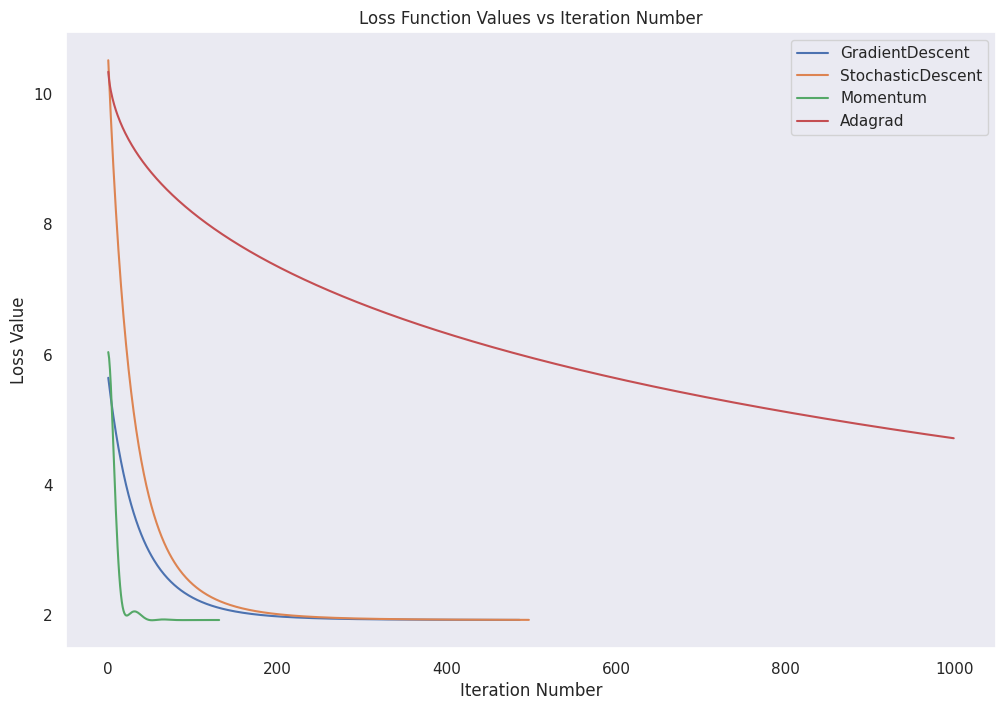

In [ ]:
loss_values = {
    'GradientDescent': [],
    'StochasticDescent': [],
    'Momentum': [],
    'Adagrad': []
}

# Train each variant and store loss values
for gd_type in loss_values.keys():
    model = LinReg(max_iter=1000, alpha=0.9, gd_type=gd_type, reg_cf=1.0)
    model.fit(X_train, y_train)
    loss_values[gd_type] = model.loss_history
plt.figure(figsize=(12, 8))
for gd_type, losses in loss_values.items():
    plt.plot(losses, label=gd_type)

plt.title('Loss Function Values vs Iteration Number')
plt.xlabel('Iteration Number')
plt.ylabel('Loss Value')
plt.legend()
plt.grid()
plt.show()


#CONCLUSIONS:
# Momentum had the best results, then GD, then SGD and the worst was Adagrad.